# Water distribution networks: EPANET-checked hydraulics, leak localization, valves

`difflow_water.network` solves a water distribution network the way EPANET does (junction heads and link flows together, Newton), but in JAX, so pressures and flows have exact gradients with respect to demands, leaks, roughness, pump speeds and valve settings.

This notebook covers:

1. EPANET's example network 3, solved and compared with EPANET 2.2's own answer.
2. Leak localization: find two leaks from twelve pressure sensors, by gradient-based fitting of leak (emitter) coefficients at every junction.
3. Roughness calibration from the same sensors.
4. Control valves: the "complementarity" and "smooth" formulations of a pressure-reducing valve, and what each does to the gradient.
5. Extended-period simulation of Net1 over a day, read from EPANET's own INP file, against EPANET; and the gradient of the end-of-day tank level.
6. Chlorine decay and water age over that day, against EPANET.

Sources and verification status: `docs/unit-operations-water.md` (network section).

In [1]:
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from difflow_water.network import NetworkModel, WaterNetwork, load_example

## 1. Net3 against EPANET

EPANET's example network 3 (92 junctions, 117 pipes, 2 pumps, 2 reservoirs, 3 tanks), at its t = 0 demands and tank levels. `load_example` returns the network and EPANET 2.2's solution (run through WNTR).

converged: True, residual 1.1e-13
max |head - EPANET| = 2.7e-05 m, max |flow - EPANET| = 0.020 L/s


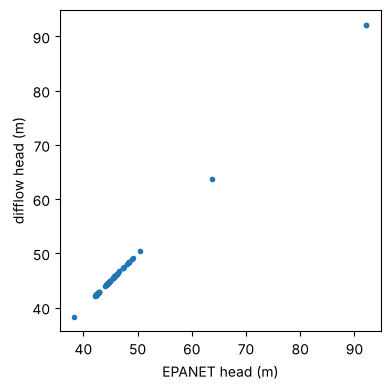

In [2]:
net, epanet = load_example("Net3")
model = NetworkModel(net)
res = model.solve()
dH = np.array([float(res["head"][i]) - epanet["head"][n] for i, n in enumerate(res["junctions"])])
dQ = np.array([float(res["flow"][i]) - epanet["flow"][n] for i, n in enumerate(res["links"])])
print(f"converged: {res['converged']}, residual {float(res['residual']):.1e}")
print(f"max |head - EPANET| = {np.abs(dH).max():.1e} m, max |flow - EPANET| = {np.abs(dQ).max() * 1e3:.3f} L/s")
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.plot([epanet["head"][n] for n in res["junctions"]], np.asarray(res["head"]), ".")
ax.set_xlabel("EPANET head (m)"); ax.set_ylabel("difflow head (m)"); ax.set_aspect("equal")
plt.tight_layout()

## 2. Leak localization

A "true" network with two leaks (emitters, `q = C p^0.5`) at junctions the fitter is not told about. Randomly placed junctions carry pressure sensors with 1 cm of noise (12, then 24 of them). The fit adjusts a non-negative leak coefficient at **every** junction to match the sensors, with a small L1 penalty that prefers few leaks; L-BFGS-B gets the exact gradient of the misfit through the network solve.

In [3]:
names = res["junctions"]
true_leaks = {"153": 4e-4, "241": 3e-4}            # ILLUSTRATIVE leaks, m^3/s per m^0.5
C_true = np.zeros(len(names))
for n, c in true_leaks.items():
    C_true[names.index(n)] = c
rng = np.random.default_rng(0)
q_leak = float(jnp.sum(model.solve({"emitter": jnp.asarray(C_true)})["emitter_flow"]))
print(f"true leak flow {q_leak * 1e3:.1f} L/s at junctions {list(true_leaks)}")

true leak flow 3.9 L/s at junctions ['153', '241']


12 sensors -- largest fitted leaks (junction, C, links to nearest true leak):
    [('237', '1.8e-04', 2), ('113', '5.1e-05', 6), ('239', '4.5e-05', 1), ('143', '3.7e-05', 6), ('241', '3.4e-05', 0)]


24 sensors -- largest fitted leaks (junction, C, links to nearest true leak):
    [('153', '2.2e-04', 0), ('151', '1.4e-04', 1), ('209', '1.1e-04', 4), ('231', '9.0e-05', 4), ('219', '2.2e-05', 7)]


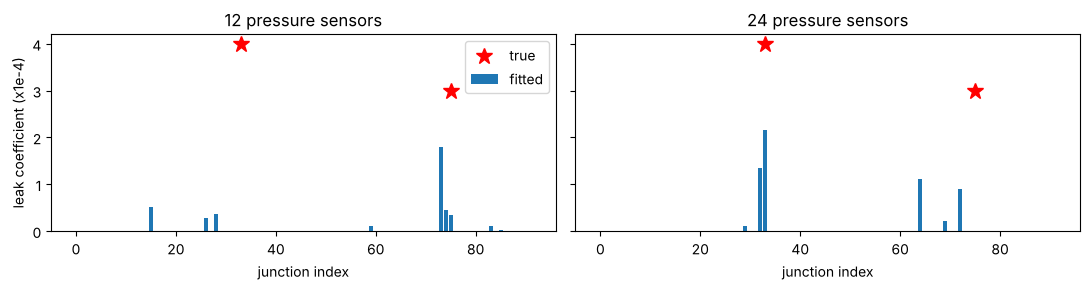

In [4]:
p0 = model.parameters()
scale = 1e-4
import collections
adj = collections.defaultdict(set)
for links in (net.pipes, net.pumps, net.valves):
    for l in links.values():
        adj[l.start].add(l.end); adj[l.end].add(l.start)

def hops(a, b):
    seen, todo = {a: 0}, [a]
    while todo:
        x = todo.pop(0)
        for y in adj[x]:
            if y not in seen:
                seen[y] = seen[x] + 1; todo.append(y)
    return seen.get(b)

def fit_leaks(sensors):
    p_meas = np.asarray(model.solve({"emitter": jnp.asarray(C_true)})["pressure"])[sensors]
    p_meas = p_meas + rng.normal(0, 0.01, len(sensors))

    @jax.jit
    def loss(c):
        p = model._solve({**p0, "emitter": c * scale})["pressure"][sensors]
        return jnp.sum((p - p_meas) ** 2) / 0.01**2 + 2.0 * jnp.sum(c)

    grad = jax.jit(jax.grad(loss))
    fit = minimize(lambda c: float(loss(jnp.asarray(c))), np.zeros(len(names)),
                   jac=lambda c: np.asarray(grad(jnp.asarray(c))), method="L-BFGS-B",
                   bounds=[(0, None)] * len(names))
    return fit.x * scale

fits = {}
for n_sensors in (12, 24):
    s = np.sort(rng.choice(len(names), n_sensors, replace=False))
    C_fit = fits[n_sensors] = fit_leaks(s)
    top = np.argsort(-C_fit)[:5]
    print(f"{n_sensors} sensors -- largest fitted leaks (junction, C, links to nearest true leak):")
    print("   ", [(names[i], f"{C_fit[i]:.1e}", min(hops(names[i], t) for t in true_leaks)) for i in top])

fig, axs = plt.subplots(1, 2, figsize=(11, 3), sharey=True)
for ax, (n_sensors, C_fit) in zip(axs, fits.items()):
    ax.bar(range(len(names)), C_fit * 1e4, label="fitted")
    ax.plot([names.index(n) for n in true_leaks], [c * 1e4 for c in true_leaks.values()], "r*", ms=12, label="true")
    ax.set_title(f"{n_sensors} pressure sensors"); ax.set_xlabel("junction index")
axs[0].set_ylabel("leak coefficient (x1e-4)"); axs[0].legend()
plt.tight_layout()

Read the printout rather than the bars alone: a fitted leak one or two links from a true one is a correct localization (the sensors cannot tell neighbours apart, so the fit spreads it over them); a fitted leak many links away is a miss. With few sensors one of the two leaks can be misplaced entirely; more sensors (or flow meters, or several demand conditions) fix that. The exact outcome depends on where the random sensors fall.

## 3. Roughness calibration

Twelve pressure sensors, now with every pipe's Hazen-Williams C 15 % below its as-built value (ageing). Fit one multiplier per pipe size class (a common calibration grouping) from the sensor pressures.

In [5]:
d = np.asarray(p0["diameter"]); is_pipe = np.asarray(model.arrays.kind) == 0
classes = np.unique(np.round(d[is_pipe], 3))
group = np.array([np.argmin(np.abs(classes - di)) if ip else -1 for di, ip in zip(d, is_pipe)])
C0 = np.asarray(p0["roughness"])
sensors = np.sort(rng.choice(len(names), 12, replace=False))
p_aged = np.asarray(model.solve({"roughness": jnp.asarray(C0 * 0.85)})["pressure"])[sensors]
p_aged = p_aged + rng.normal(0, 0.01, len(sensors))

@jax.jit
def loss_c(m):
    mult = jnp.where(jnp.asarray(group) >= 0, m[jnp.maximum(jnp.asarray(group), 0)], 1.0)
    p = model._solve({**p0, "roughness": jnp.asarray(C0) * mult})["pressure"][sensors]
    return jnp.sum((p - p_aged) ** 2) / 0.01**2 + 10.0 * jnp.sum((m - 1.0) ** 2)

g_c = jax.jit(jax.grad(loss_c))
fit_c = minimize(lambda m: float(loss_c(jnp.asarray(m))), np.ones(len(classes)),
                 jac=lambda m: np.asarray(g_c(jnp.asarray(m))), method="L-BFGS-B",
                 bounds=[(0.5, 1.2)] * len(classes))
print(fit_c.message)
for c, m in zip(classes, fit_c.x):
    print(f"pipes of {c * 1000:5.0f} mm: C multiplier {m:.3f} (true 0.85)")

CONVERGENCE: RELATIVE REDUCTION OF F <= FACTR*EPSMCH
pipes of   203 mm: C multiplier 0.820 (true 0.85)
pipes of   254 mm: C multiplier 0.838 (true 0.85)
pipes of   305 mm: C multiplier 0.913 (true 0.85)
pipes of   356 mm: C multiplier 1.000 (true 0.85)
pipes of   406 mm: C multiplier 0.832 (true 0.85)
pipes of   457 mm: C multiplier 1.000 (true 0.85)
pipes of   508 mm: C multiplier 0.791 (true 0.85)
pipes of   610 mm: C multiplier 0.845 (true 0.85)
pipes of   762 mm: C multiplier 0.845 (true 0.85)
pipes of  2515 mm: C multiplier 1.000 (true 0.85)


Size classes the sensors barely see stay near the prior (1.0): the regularization keeps them there instead of letting noise move them.

## 4. A pressure-reducing valve, two ways

A reservoir feeds a zone through a PRV; wide open, the valve would deliver about 29 m downstream. Sweep the setting across the point where the valve goes from active to wide open (upstream pressure too low to throttle) and look at the downstream pressure and its derivative with respect to the setting. The **complementarity** formulation switches sharply, as EPANET does; the **smooth** one rounds the switch so the derivative is continuous.

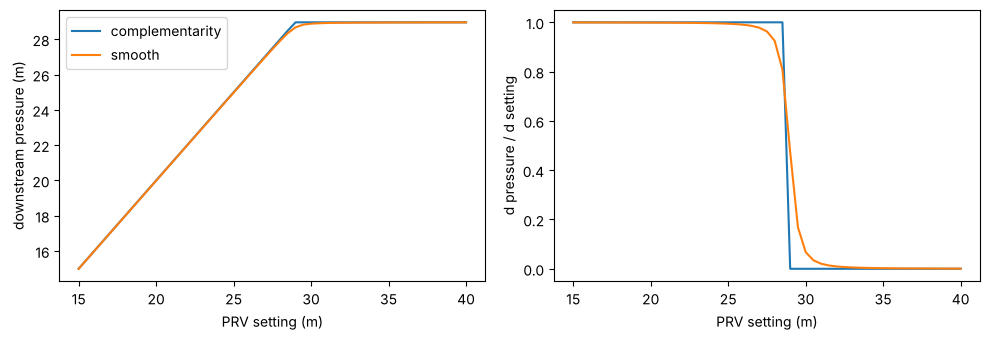

In [6]:
def prv_net():
    n = WaterNetwork()
    n.add_reservoir("R", head=60.0)
    n.add_junction("U", elevation=0.0, demand=0.002)
    n.add_junction("D", elevation=0.0, demand=0.02)
    n.add_pipe("P1", "R", "U", 2000.0, 0.15, 110.0)
    n.add_valve("V", "U", "D", "PRV", diameter=0.15, setting=30.0)
    return n

settings = np.linspace(15.0, 40.0, 51)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
for form, kw in (("complementarity", {}), ("smooth", {"smoothing": 0.3})):
    m = NetworkModel(prv_net(), valve_formulation=form, **kw)
    iD, iV = m.arrays.junctions.index("D"), m.arrays.links.index("V")
    base = m.parameters()
    f = jax.jit(lambda s: m._solve({**base, "setting": base["setting"].at[iV].set(s)})["pressure"][iD])
    df = jax.jit(jax.grad(f))
    p = [float(f(s)) for s in settings]
    g = [float(df(s)) for s in settings]
    axs[0].plot(settings, p, label=form); axs[1].plot(settings, g, label=form)
axs[0].set_xlabel("PRV setting (m)"); axs[0].set_ylabel("downstream pressure (m)")
axs[1].set_xlabel("PRV setting (m)"); axs[1].set_ylabel("d pressure / d setting")
axs[0].legend(); plt.tight_layout()

Below the switch the valve holds the setting (derivative 1); above it the valve is wide open and the setting no longer matters (derivative 0). The smoothing width here (0.3, in units of 1 m and 1 L/s) is exaggerated so the rounding is visible; the default 1e-3 is indistinguishable from the sharp answer except within millimetres of the switch.

## 5. A day of Net1

`read_inp` reads EPANET's own input file (patterns, controls, times) and `simulate` steps through the day as EPANET does: tank levels advance with their net inflow, demands follow their pattern, and the pump runs on the tank-level controls (on below 110 ft, off above 140 ft). The dashed line is EPANET 2.2's answer (run through WNTR, `benchmarks/wntr/eps/Net1.json`).

max tank level difference: 1.1e-04 m


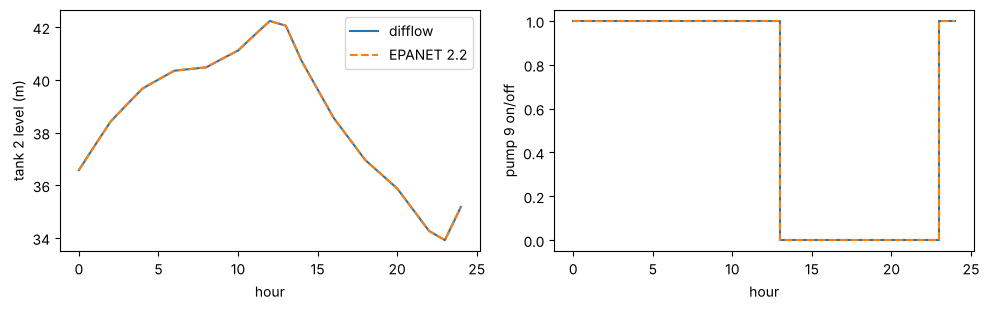

In [7]:
import json
from difflow_water.network import example_inp, read_inp, simulate

net1, sched = read_inp(example_inp("Net1"))
m1 = NetworkModel(net1)
day = simulate(net1, sched, model=m1)
ref = json.load(open("../benchmarks/wntr/eps/Net1.json"))
ip = m1.arrays.links.index("9")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(day["time"] / 3600, np.asarray(day["tank_level"])[:, 0], label="difflow")
ax[0].plot(np.asarray(ref["time"]) / 3600, ref["tank_level"]["2"], "--", label="EPANET 2.2")
ax[0].set_xlabel("hour"); ax[0].set_ylabel("tank 2 level (m)"); ax[0].legend()
ax[1].step(day["time"] / 3600, np.asarray(day["status"])[:, ip], where="post", label="difflow")
ax[1].step(np.asarray(ref["time"]) / 3600, ref["status"]["9"], "--", where="post", label="EPANET 2.2")
ax[1].set_xlabel("hour"); ax[1].set_ylabel("pump 9 on/off")
plt.tight_layout()
print("max tank level difference: %.1e m" % np.max(np.abs(np.asarray(day["tank_level"])[:, 0] - np.asarray(ref["tank_level"]["2"]))))

**Gradients through the day.** The run above recorded a `plan` (the statuses of every step and what set its length). Replaying it with traced parameters gives the derivative of the end-of-day tank level with respect to, here, the pump speed and every pipe's roughness, with the pump's switch times moving as they should.

In [8]:
p1 = m1.parameters()

def end_level(speed, rough):
    run = simulate(net1, sched, model=m1, plan=day["plan"], params={"speed": speed, "roughness": rough})
    return run["tank_level"][-1, 0]

d_speed, d_rough = jax.grad(end_level, argnums=(0, 1))(p1["speed"], p1["roughness"])
print(f"d(level at 24 h)/d(pump 9 speed) = {float(d_speed[ip]):.2f} m per unit speed ratio")
top = np.argsort(-np.abs(np.asarray(d_rough)))[:3]
print("most influential pipes (d level / d C):", [(m1.arrays.links[i], f"{float(d_rough[i]):.3f} m") for i in top])

d(level at 24 h)/d(pump 9 speed) = 5.90 m per unit speed ratio
most influential pipes (d level / d C): [('10', '0.003 m'), ('11', '0.002 m'), ('111', '0.001 m')]


## 6. Chlorine and water age over the day

`water_quality` runs EPANET's Lagrangian transport over the simulation above: parcels of water move through the pipes without mixing, blend completely at junctions and in the tank, and chlorine decays in the bulk water (-0.5/day) and at the pipe wall (-1 ft/day, limited by mass transfer), as Net1's input file specifies. Not differentiable yet (the parcel bookkeeping is discrete).

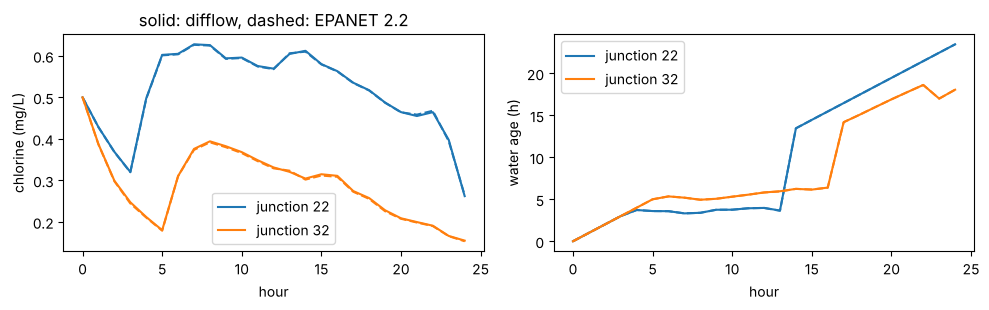

In [9]:
from difflow_water.network import water_quality

cl = water_quality(net1, sched, day)
ref_age = json.load(open("../benchmarks/wntr/eps/Net1_age.json"))
sched_age = read_inp(example_inp("Net1"))[1]
sched_age.quality_options["mode"] = "AGE"
age = water_quality(net1, sched_age, day)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for nd, col in (("22", "C0"), ("32", "C1")):
    j = cl["nodes"].index(nd)
    ax[0].plot(cl["time"] / 3600, cl["quality"][:, j], color=col, label=f"junction {nd}")
    ax[0].plot(np.asarray(ref["time"]) / 3600, np.asarray(ref["quality"][nd]) * 1e3, "--", color=col)
    ax[1].plot(age["time"] / 3600, age["quality"][:, j], color=col, label=f"junction {nd}")
    ax[1].plot(np.asarray(ref_age["time"]) / 3600, ref_age["quality"][nd], "--", color=col)
ax[0].set_ylabel("chlorine (mg/L)"); ax[1].set_ylabel("water age (h)")
for a_ in ax:
    a_.set_xlabel("hour"); a_.legend()
ax[0].set_title("solid: difflow, dashed: EPANET 2.2")
plt.tight_layout()

## Notes

- The leak and roughness values are ILLUSTRATIVE test cases, not data.